In [1]:
!pip -q install "transformers>=4.45,<5" xgboost scikit-learn pandas numpy matplotlib torch

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


Device: cpu
Upload genuine daily CSV with date and pm25 columns


Saving termiz_pm25_10_rows.csv to termiz_pm25_10_rows.csv
Data: 2891 days 2018-10-01 2026-08-30 features: ['pm25']
     split      start        end  days
     train 2018-10-01 2024-04-14  2023
validation 2024-04-15 2025-06-22   434
      test 2025-06-23 2026-08-30   434
Common test forecast origins: 14 first: 2025-06-23 00:00:00 last: 2026-07-18 00:00:00

===== HORIZON 7 =====
Trained PatchTST_univariate

===== HORIZON 14 =====
Trained PatchTST_univariate

===== HORIZON 30 =====
Trained PatchTST_univariate

=== MODEL COMPARISON ===
               model  horizon  n_test_dates  n_origins       MAE      RMSE        R2  sMAPE_percent
PatchTST_univariate        7            98         14 23.648976 32.595393  0.008002      31.748545
              Ridge        7            98         14 24.127339 34.674203 -0.122564      32.738595
            XGBoost        7            98         14 27.875328 39.214173 -0.435768      38.298691
               LSTM        7            98         14 28.934376 4

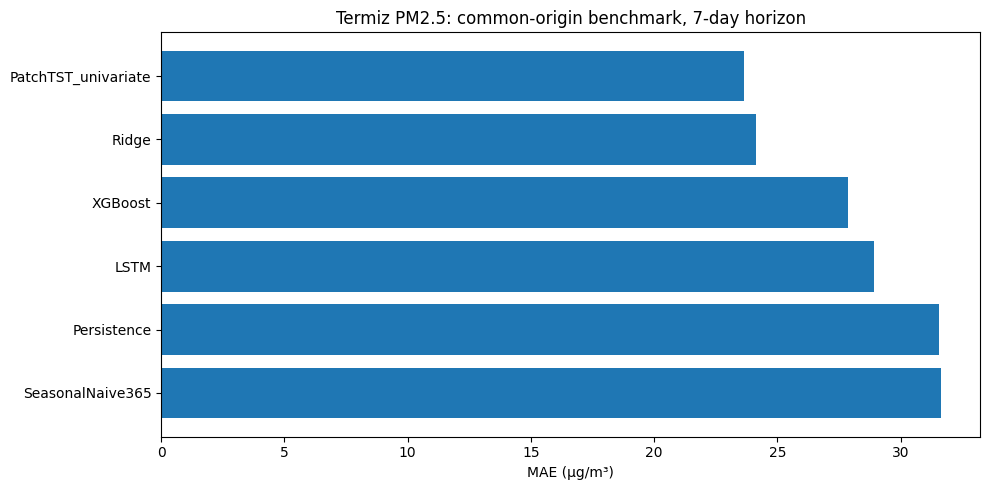

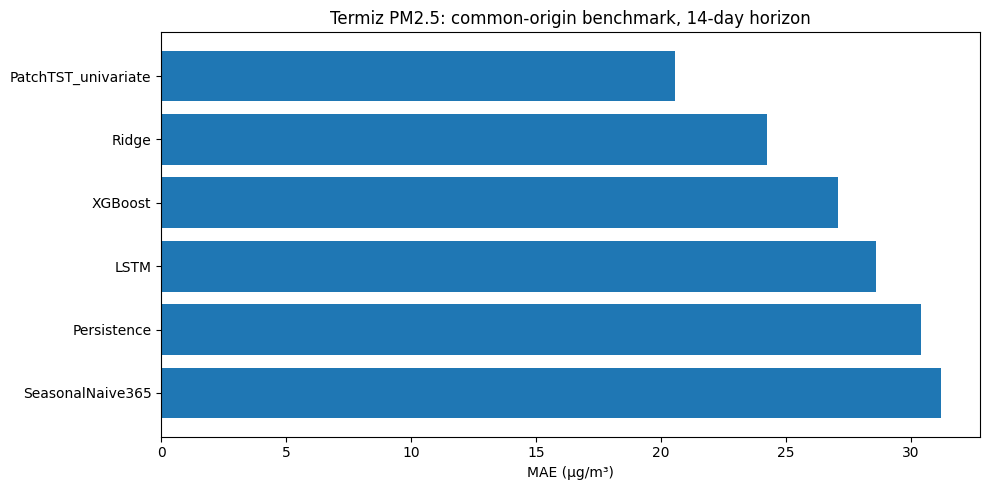

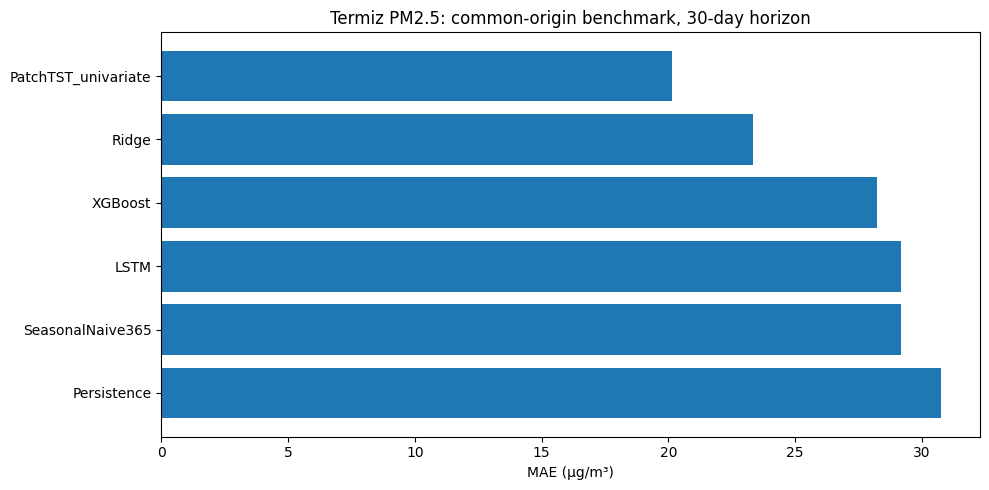

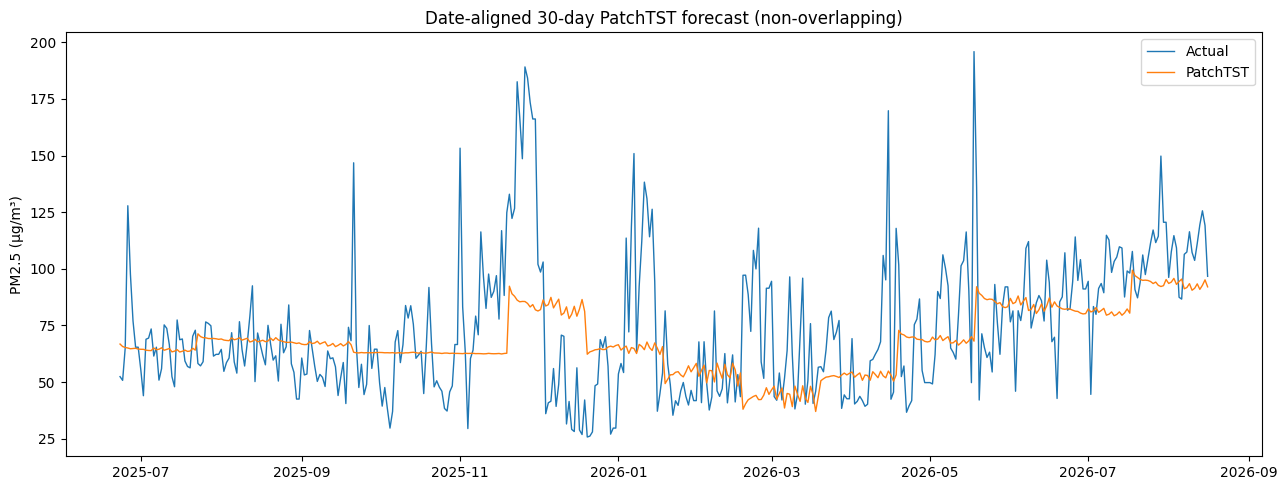

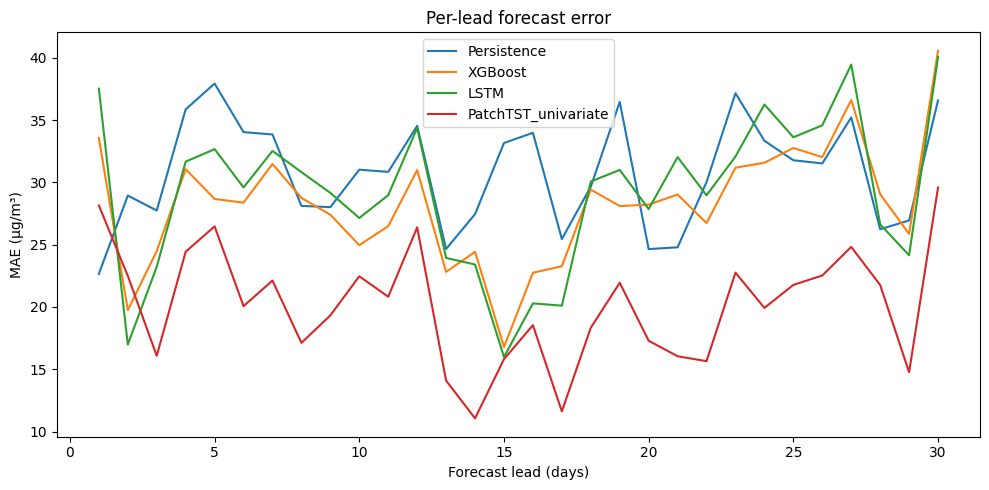

DONE: termiz_benchmark_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
"""Termiz PM2.5 research benchmark. Run in Colab after installing requirements."""
import os, json, copy, random, warnings, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from transformers import PatchTSTConfig, PatchTSTForPrediction

SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
OUT=Path('termiz_benchmark_results'); OUT.mkdir(exist_ok=True)
CONTEXT=90
HORIZONS=[7,14,30]
EPOCHS=35
PATIENCE=7
BATCH=64
TRAIN_STRIDE=3
EVAL_STRIDE=30  # Non-overlapping 30-day forecast origins; same origin dates across horizons
print('Device:',DEVICE)

# === Upload genuine daily dataset ===
try:
    from google.colab import files
    print('Upload genuine daily CSV with date and pm25 columns')
    uploaded=files.upload()
    file_name=next(iter(uploaded))
except ImportError:
    file_name=input('CSV path: ').strip()
raw=pd.read_csv(file_name)
raw.columns=[str(c).lower().strip() for c in raw.columns]
alias={'pm2.5':'pm25','pm2_5':'pm25','pm25_ug_m3':'pm25','temp':'temperature','temp_2m':'temperature','relative_humidity':'humidity','rh2m':'humidity','ws10m':'wind_speed','wind':'wind_speed'}
raw=raw.rename(columns={a:b for a,b in alias.items() if a in raw and b not in raw})
if not {'date','pm25'}.issubset(raw.columns): raise ValueError('Required CSV columns: date, pm25')
raw['date']=pd.to_datetime(raw['date'],errors='coerce')
raw=raw.dropna(subset=['date']).sort_values('date').drop_duplicates('date',keep='last').set_index('date')
raw.index=raw.index.normalize(); raw=raw[~raw.index.duplicated(keep='last')]
optional=['temperature','humidity','wind_speed','pm10','precipitation','pressure']
cols=['pm25']+[c for c in optional if c in raw.columns]
for c in cols: raw[c]=pd.to_numeric(raw[c],errors='coerce')
df=raw[cols].asfreq('D')
if (df['pm25']<0).any(): raise ValueError('Negative PM2.5 found; fix source values first')
missing=df.isna().sum().to_dict()
# Causal fill only: never use later target values to fill earlier values.
for c in cols: df[c]=df[c].ffill(limit=2)
if df.pm25.isna().any():
    raise ValueError('Long PM2.5 gaps remain. Select a continuous period or resolve gaps from source. Missing days: '+str(df.index[df.pm25.isna()][:8].tolist()))
optional=[c for c in optional if c in cols and not df[c].isna().any()]
cols=['pm25']+optional; df=df[cols].copy()
if len(df)<850: raise ValueError('Need at least 850 consecutive days for this experiment')
print('Data:',len(df),'days',df.index.min().date(),df.index.max().date(),'features:',cols)

# Fixed chronological 70/15/15 raw-date partitions. Training windows: labels must remain in split.
n=len(df); train_end=n*70//100; val_end=n*85//100
if train_end<=CONTEXT+30 or val_end-train_end<30 or n-val_end<30: raise ValueError('Split too small')
idx=df.index
split_table=pd.DataFrame([{'split':'train','start':str(idx[0].date()),'end':str(idx[train_end-1].date()),'days':train_end},
{'split':'validation','start':str(idx[train_end].date()),'end':str(idx[val_end-1].date()),'days':val_end-train_end},
{'split':'test','start':str(idx[val_end].date()),'end':str(idx[-1].date()),'days':n-val_end}])
split_table.to_csv(OUT/'split_metadata.csv',index=False)
(OUT/'data_quality.json').write_text(json.dumps({'file':file_name,'raw_rows':len(raw),'daily_rows':len(df),'missing_before_causal_fill':missing,'features':cols,'seed':SEED,'context':CONTEXT,'eval_stride':EVAL_STRIDE,'warning':'Forward fill up to 2 days; no future-value interpolation'},indent=2),encoding='utf-8')
print(split_table.to_string(index=False))

# A single set of forecast origins shared by ALL methods and horizons.
# Forecast labels must fit within the test partition. Step=30 ensures no overlapping
# predictions for the longest horizon (30), and common origins for all horizons.
origins=np.arange(max(val_end,CONTEXT,365),n-max(HORIZONS)+1,EVAL_STRIDE,dtype=int)
if len(origins)<2: raise ValueError('Too few common test origins. Need a longer test period.')
print('Common test forecast origins:',len(origins),'first:',idx[origins[0]],'last:',idx[origins[-1]])

class Windows(Dataset):
    def __init__(self,arr,start,end,horizon,context=CONTEXT,stride=TRAIN_STRIDE):
        self.arr=arr; self.context=context; self.horizon=horizon
        self.indices=list(range(max(context,start),end-horizon+1,stride))
    def __len__(self):return len(self.indices)
    def __getitem__(self,k):
        i=self.indices[k]
        return torch.tensor(self.arr[i-self.context:i],dtype=torch.float32),torch.tensor(self.arr[i:i+self.horizon],dtype=torch.float32)

def metrics(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    return {'MAE':float(mean_absolute_error(y,p)), 'RMSE':float(np.sqrt(mean_squared_error(y,p))),
            'R2':float(r2_score(y,p)) if len(y)>1 else float('nan'),
            'sMAPE_percent':float(np.mean(200*np.abs(y-p)/(np.abs(y)+np.abs(p)+1e-8)))}

def inverse_pm(z,sc):return np.asarray(z)*sc.scale_[0]+sc.mean_[0]

def patch_model(channels,horizon):
    cfg=PatchTSTConfig(num_input_channels=channels,context_length=CONTEXT,prediction_length=horizon,
        patch_length=15,patch_stride=5,d_model=64,num_hidden_layers=2,num_attention_heads=4,
        ffn_dim=128,dropout=0.15,attention_dropout=0.1,loss='mse')
    return PatchTSTForPrediction(cfg).to(DEVICE)

class LSTMForecaster(nn.Module):
    def __init__(self,channels,horizon):
        super().__init__();self.lstm=nn.LSTM(channels,64,batch_first=True,num_layers=2,dropout=.15)
        self.head=nn.Linear(64,horizon)
    def forward(self,x):return self.head(self.lstm(x)[0][:,-1,:])

def train_torch(model,train_arr,val_arr,horizon,kind,run_name):
    tr=Windows(train_arr,0,train_end,horizon)
    # Validation contexts include previous train dates, but validation LABELS only.
    va=Windows(val_arr,train_end,val_end,horizon,stride=7)
    if not len(tr) or not len(va):raise ValueError('Empty train/validation windows')
    tl=DataLoader(tr,batch_size=BATCH,shuffle=True);vl=DataLoader(va,batch_size=BATCH)
    opt=torch.optim.AdamW(model.parameters(),lr=2e-4,weight_decay=1e-4)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=3)
    best=np.inf;weights=None;wait=0;logs=[]
    for epoch in range(1,EPOCHS+1):
        model.train();tr_loss=[]
        for x,y in tl:
            x=x.to(DEVICE);y=y.to(DEVICE);opt.zero_grad()
            if kind=='patch': loss=model(past_values=x,future_values=y).loss
            else: loss=nn.functional.mse_loss(model(x),y[:,:,0])
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);opt.step();tr_loss.append(loss.item())
        model.eval();va_loss=[]
        with torch.no_grad():
            for x,y in vl:
                x=x.to(DEVICE);y=y.to(DEVICE)
                if kind=='patch': loss=model(past_values=x,future_values=y).loss
                else:loss=nn.functional.mse_loss(model(x),y[:,:,0])
                va_loss.append(loss.item())
        v=float(np.mean(va_loss));sched.step(v)
        logs.append({'epoch':epoch,'train_loss':float(np.mean(tr_loss)),'val_loss':v})
        if v<best-1e-5:best=v;weights=copy.deepcopy(model.state_dict());wait=0
        else:wait+=1
        if wait>=PATIENCE:break
    model.load_state_dict(weights)
    pd.DataFrame(logs).to_csv(OUT/f'loss_{run_name}.csv',index=False)
    return model

all_rows=[]; all_metrics=[]; ablation=[]
for horizon in HORIZONS:
    print('\n===== HORIZON',horizon,'=====')
    # Train-only fit of each scaler. Multivariate model predicts all channels; target is channel 0.
    variants={'univariate':['pm25']}
    if len(cols)>1: variants['multivariate']=cols
    for variant,features in variants.items():
        sc=StandardScaler().fit(df.iloc[:train_end][features].values)
        arr=sc.transform(df[features].values).astype('float32')
        patch=train_torch(patch_model(len(features),horizon),arr,arr,horizon,'patch',f'patch_{variant}_{horizon}')
        patch.eval();out=[]
        with torch.no_grad():
            for origin in origins:
                x=torch.tensor(arr[origin-CONTEXT:origin],dtype=torch.float32).unsqueeze(0).to(DEVICE)
                pred=patch(past_values=x).prediction_outputs.squeeze(0).cpu().numpy()
                if pred.ndim==1:pred=pred[:,None]
                out.append(np.maximum(0,inverse_pm(pred[:horizon,0],sc)))
        out=np.asarray(out)
        name='PatchTST_'+variant
        for oi,origin in enumerate(origins):
            for lead in range(horizon):
                all_rows.append({'model':name,'horizon':horizon,'origin':str(idx[origin].date()),
                    'date':str(idx[origin+lead].date()),'lead':lead+1,'actual':float(df.pm25.iloc[origin+lead]),
                    'predicted':float(out[oi,lead])})
        patch.save_pretrained(str(OUT/f'model_{variant}_{horizon}'))
        ablation.append({'variant':variant,'horizon':horizon,'channels':','.join(features)})
        print('Trained',name)

    # Baselines and classical models: same origins and test targets
    train_y=df.pm25.iloc[:train_end].values
    # Use univariate, train-only scaler for LSTM and classical methods
    sc=StandardScaler().fit(train_y.reshape(-1,1))
    z=sc.transform(df[['pm25']].values).astype('float32')
    train_starts=np.arange(CONTEXT,train_end-horizon+1,3)
    X=np.stack([z[i-CONTEXT:i,0] for i in train_starts])
    Y=np.stack([z[i:i+horizon,0] for i in train_starts])
    ridge=Ridge(alpha=10.0).fit(X,Y)
    # XGBoost: one multi-output regressor per lead; moderate trees for Colab runtime
    xgb=MultiOutputRegressor(XGBRegressor(n_estimators=120,max_depth=3,learning_rate=.05,
        subsample=.85,colsample_bytree=.9,objective='reg:squarederror',n_jobs=2,random_state=SEED))
    xgb.fit(X,Y)
    lstm=train_torch(LSTMForecaster(1,horizon).to(DEVICE),z,z,horizon,'lstm',f'lstm_{horizon}')
    lstm.eval()
    for origin in origins:
        observed=float(df.pm25.iloc[origin-1])
        seasonal=[float(df.pm25.iloc[origin+lead-365]) for lead in range(horizon)]
        window=z[origin-CONTEXT:origin,0].reshape(1,-1)
        preds={'Persistence':np.repeat(observed,horizon),
               'SeasonalNaive365':np.array(seasonal),
               'Ridge':np.maximum(0,inverse_pm(ridge.predict(window).ravel(),sc)),
               'XGBoost':np.maximum(0,inverse_pm(xgb.predict(window).ravel(),sc))}
        with torch.no_grad():
            x=torch.tensor(z[origin-CONTEXT:origin],dtype=torch.float32).unsqueeze(0).to(DEVICE)
            preds['LSTM']=np.maximum(0,inverse_pm(lstm(x).squeeze(0).cpu().numpy(),sc))
        for name,forecast in preds.items():
            for lead in range(horizon):
                all_rows.append({'model':name,'horizon':horizon,'origin':str(idx[origin].date()),
                    'date':str(idx[origin+lead].date()),'lead':lead+1,'actual':float(df.pm25.iloc[origin+lead]),
                    'predicted':float(forecast[lead])})

preds=pd.DataFrame(all_rows)
preds.to_csv(OUT/'all_predictions_by_origin_lead.csv',index=False)
# No repeated target dates within a model+horizon: eval stride >= max horizon
assert not preds.duplicated(['model','horizon','date']).any(), 'Overlapping evaluation dates!'
for (name,horizon),g in preds.groupby(['model','horizon']):
    all_metrics.append({'model':name,'horizon':horizon,'n_test_dates':len(g),
                        'n_origins':g.origin.nunique(),**metrics(g.actual,g.predicted)})
summary=pd.DataFrame(all_metrics).sort_values(['horizon','MAE'])
summary.to_csv(OUT/'model_comparison.csv',index=False)
print('\n=== MODEL COMPARISON ===\n',summary.to_string(index=False))
lead_rows=[]
for (name,horizon,lead),g in preds.groupby(['model','horizon','lead']):
    lead_rows.append({'model':name,'horizon':horizon,'lead':lead,**metrics(g.actual,g.predicted)})
lead_df=pd.DataFrame(lead_rows)
lead_df.to_csv(OUT/'per_lead_metrics.csv',index=False)
# Comparison chart: MAE for each method on same horizon
for horizon in HORIZONS:
    sub=summary[summary.horizon==horizon].sort_values('MAE')
    fig,ax=plt.subplots(figsize=(10,5))
    ax.barh(sub.model,sub.MAE);ax.invert_yaxis();ax.set_xlabel('MAE (µg/m³)')
    ax.set_title(f'Termiz PM2.5: common-origin benchmark, {horizon}-day horizon')
    fig.tight_layout();fig.savefig(OUT/f'comparison_h{horizon}.png',dpi=160);plt.show()
# Date-aligned actual vs predicted for 30-day horizon
sub=preds[(preds.horizon==30)&(preds.model=='PatchTST_univariate')].sort_values('date')
fig,ax=plt.subplots(figsize=(13,5));ax.plot(pd.to_datetime(sub.date),sub.actual,label='Actual',lw=1)
ax.plot(pd.to_datetime(sub.date),sub.predicted,label='PatchTST',lw=1)
ax.set_title('Date-aligned 30-day PatchTST forecast (non-overlapping)');ax.set_ylabel('PM2.5 (µg/m³)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'actual_vs_patchtst.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(10,5))
for name in ['Persistence','XGBoost','LSTM','PatchTST_univariate','PatchTST_multivariate']:
    g=lead_df[(lead_df.model==name)&(lead_df.horizon==30)].sort_values('lead')
    if len(g):ax.plot(g.lead,g.MAE,label=name)
ax.set_xlabel('Forecast lead (days)');ax.set_ylabel('MAE (µg/m³)');ax.set_title('Per-lead forecast error')
ax.legend();fig.tight_layout();fig.savefig(OUT/'per_lead_mae.png',dpi=160);plt.show()
# Seasonal errors for date-aligned test forecasts
season=preds.copy();season['month']=pd.to_datetime(season.date).dt.month
season['abs_error']=(season.actual-season.predicted).abs()
season.groupby(['model','horizon','month'],as_index=False).abs_error.mean().to_csv(OUT/'monthly_error.csv',index=False)
pd.DataFrame(ablation).to_csv(OUT/'ablation_metadata.csv',index=False)
with zipfile.ZipFile('termiz_benchmark_results.zip','w',zipfile.ZIP_DEFLATED) as archive:
    for p in OUT.rglob('*'):
        if p.is_file():archive.write(p,p.relative_to(OUT.parent))
print('DONE: termiz_benchmark_results.zip')
try:
    from google.colab import files
    files.download('termiz_benchmark_results.zip')
except ImportError:pass
